In [3]:
#Ensure you have installed the required libraries, including pandas, matplotlib, and opencv-python for image handling.
#!pip install pandas matplotlib opencv-python




In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import cv2



In [5]:
#Load the classes_rgb_values.csv and video_info.csv files to inspect the data distribution and class information.

# Define paths to the metadata files
classes_rgb_values_path = r"data\classes_rgb_values.csv"
video_info_path = r"data\video_info.csv"

# Load CSV files into DataFrames
class_rgb_values = pd.read_csv(classes_rgb_values_path)
video_info = pd.read_csv(video_info_path)

# Display the first few rows of each to understand their structure
display(class_rgb_values.head())
display(video_info.head())



,index,semantic_class,rgb_values,relative_percentile_frequency
0,0,Traffic Sign,"[220,2200]",0.05
1,1,Building,"[70,70,70]",14.08
2,2,Fence,"[190,153,153]",0.28
3,3,Other,"[250,170,160]",0.29
4,4,Pedestrian,"[220,20,60]",1.02


,Index,duration_seconds,weather,driving_scenario,n_images
0,0,30.4,Sunny,Driving,305
1,1,34.1,Sunny,Driving + Traffic am,342
2,2,36.2,Sunny,Driving,363
3,3,35.0,Sunny,Driving + Traffic am,350
4,4,33.4,Sunny,Driving,335


Index(['Index', 'duration_seconds', 'weather', 'driving_scenario', 'n_images'],
      dtype='str')


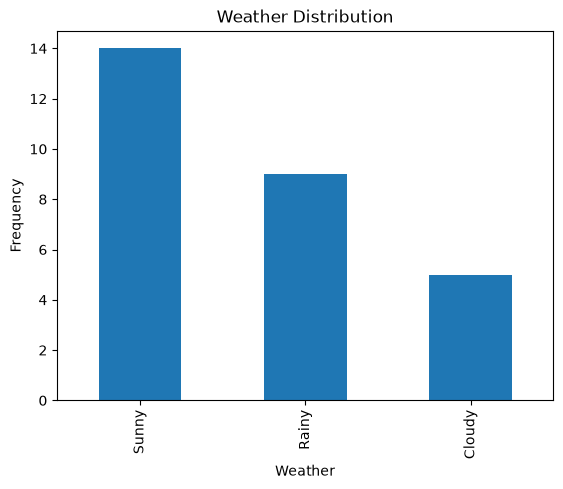

In [6]:
# Use video_info.csv to analyze details such as the weather distribution and the duration of each video sequence.

# Check column names and ensure 'weather' and 'duration' columns exist
print(video_info.columns)

# Weather distribution
weather_distribution = video_info['weather'].value_counts()
weather_distribution.plot(kind='bar', title='Weather Distribution')
plt.xlabel('Weather')
plt.ylabel('Frequency')
plt.show()



In [7]:
print(video_info.columns)


Index(['Index', 'duration_seconds', 'weather', 'driving_scenario', 'n_images'],
      dtype='str')


In [8]:
display(video_info.head())


,Index,duration_seconds,weather,driving_scenario,n_images
0,0,30.4,Sunny,Driving,305
1,1,34.1,Sunny,Driving + Traffic am,342
2,2,36.2,Sunny,Driving,363
3,3,35.0,Sunny,Driving + Traffic am,350
4,4,33.4,Sunny,Driving,335


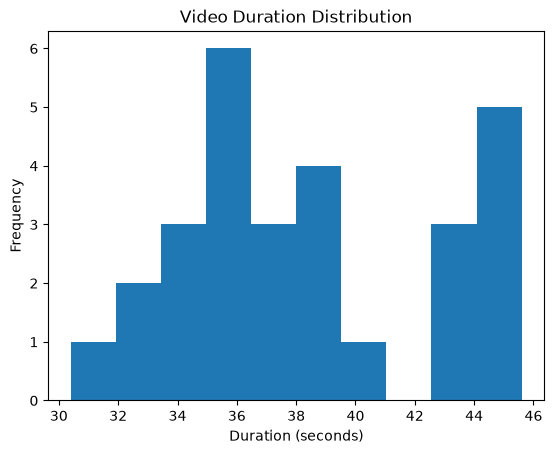

In [9]:
# Video duration distribution
video_info['duration_seconds'].plot(kind='hist', title='Video Duration Distribution')
plt.xlabel('Duration (seconds)')
plt.ylabel('Frequency')
plt.show()

In [10]:
print(class_rgb_values.columns)

Index(['index', 'semantic_class', 'rgb_values',
       'relative_percentile_frequency'],
      dtype='str')


In [11]:
display(class_rgb_values.head())


,index,semantic_class,rgb_values,relative_percentile_frequency
0,0,Traffic Sign,"[220,2200]",0.05
1,1,Building,"[70,70,70]",14.08
2,2,Fence,"[190,153,153]",0.28
3,3,Other,"[250,170,160]",0.29
4,4,Pedestrian,"[220,20,60]",1.02


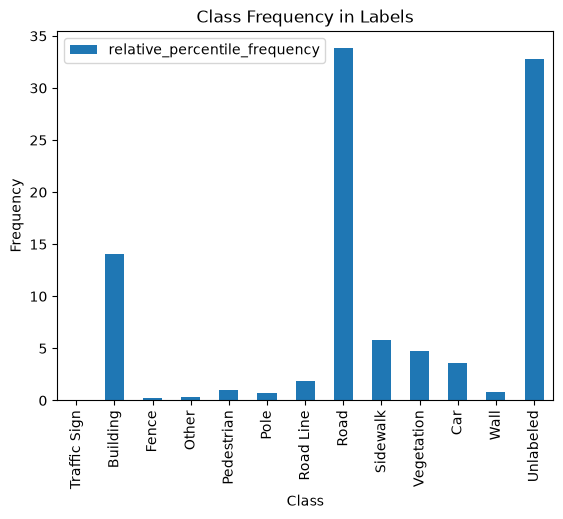

In [12]:
#This file provides RGB values for each semantic class. Use it to explore the frequency of different semantic classes.

# Class Frequency Distribution
class_rgb_values.plot(kind='bar', x='semantic_class', y='relative_percentile_frequency', title='Class Frequency in Labels')
plt.xlabel('Class')
plt.ylabel('Frequency')
plt.show()

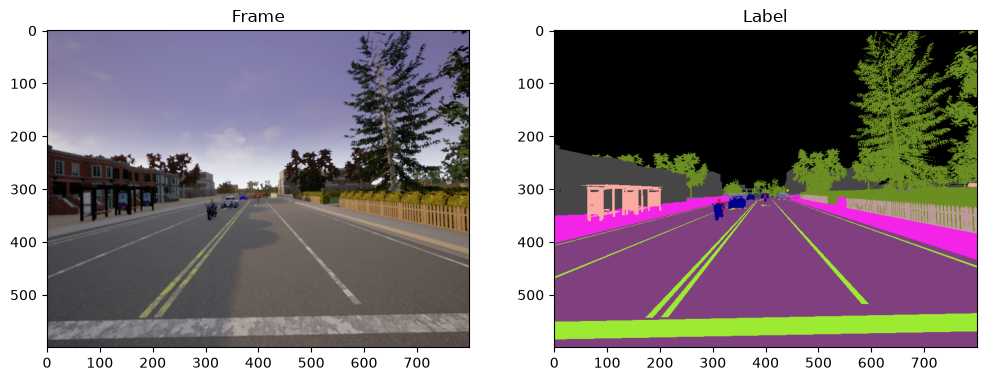

In [13]:
#To visually inspect the dataset, load a few sample frames and their corresponding semantic labels. Adjust the paths to the images and labels folders.


# Define paths to images and labels directories
images_dir = r"data\images"
labels_dir = r"data\labels"
# Load and display a sample image and its corresponding label
sample_image_path = os.path.join(images_dir, "Video_000", "v000_0000.png")  # Adjust filename as needed
sample_label_path = os.path.join(labels_dir, "Video_000", "v000_0000.png")  # Corresponding label file

# Load and display the image
image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Load and display the label
label = cv2.imread(sample_label_path)
label = cv2.cvtColor(label, cv2.COLOR_BGR2RGB)

# Display side-by-side
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Frame')

plt.subplot(1, 2, 2)
plt.imshow(label)
plt.title('Label')
plt.show()


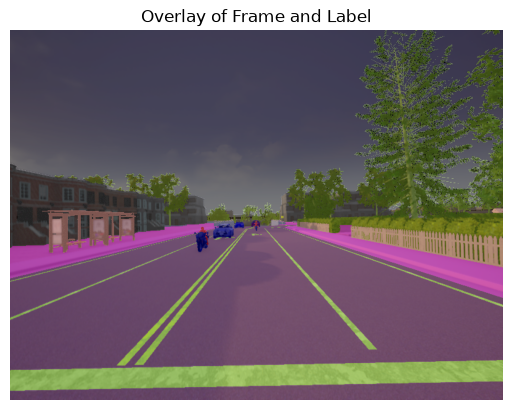

In [14]:
# To get a better sense of the labeled data, overlay the labels on the original frames using transparency.

alpha = 0.5  # Transparency factor
overlay = cv2.addWeighted(image, alpha, label, 1 - alpha, 0)

# Display the overlay
plt.imshow(overlay)
plt.title('Overlay of Frame and Label')
plt.axis('off')
plt.show()


In [15]:
# If class_rgb_values.csv contains RGB values for each semantic class, you can use these values to colorize the bars in a class frequency plot.
# Assuming 'class_name', 'frequency', and 'R', 'G', 'B' columns in class_rgb_values

# Create a custom color mapping for each class based on RGB values
print(class_rgb_values.columns)


Index(['index', 'semantic_class', 'rgb_values',
       'relative_percentile_frequency'],
      dtype='str')


In [ ]:
import torch, os
print(torch.cuda.is_available())
print(os.listdir("data"))

True
['classes_rgb_values.csv', 'images', 'labels', 'video_info.csv']


**DE AICI INCEPE CODUL PROPRIU ZIS**

,index,semantic_class,rgb,relative_percentile_frequency
0,0,Traffic Sign,"(220, 220, 0)",0.05
1,1,Building,"(70, 70, 70)",14.08
2,2,Fence,"(190, 153, 153)",0.28
3,3,Other,"(250, 170, 160)",0.29
4,4,Pedestrian,"(220, 20, 60)",1.02
5,5,Pole,"(153, 153, 153)",0.74
6,6,Road Line,"(157, 234, 50)",1.86
7,7,Road,"(128, 64, 128)",33.80
8,8,Sidewalk,"(244, 35, 232)",5.85
9,9,Vegetation,"(107, 142, 35)",4.78


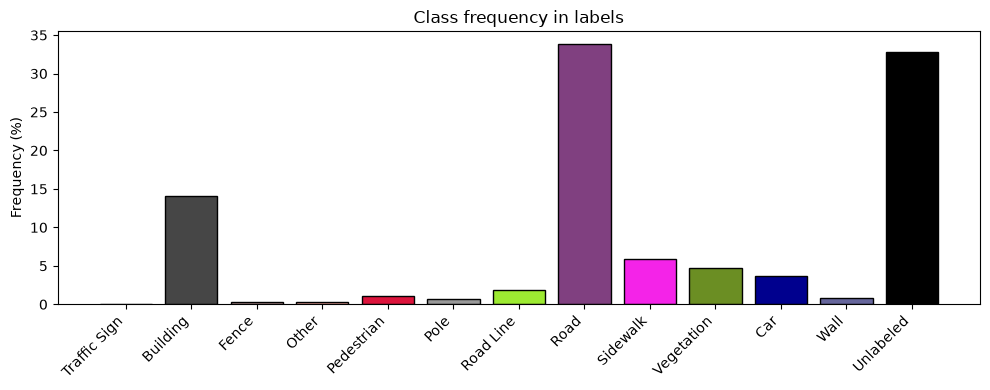

Image size: (600, 800, 3), classes found: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9), np.uint8(10), np.uint8(11), np.uint8(12)]
Pixels with an unknown colour: 0.00%


In [17]:
import numpy as np
import ast

# --- 1. Read class colours, fixing the broken Traffic Sign row ---
def parse_rgb(s):
    vals = ast.literal_eval(s)
    if len(vals) != 3:          # "[220,2200]" -> should be [220,220,0]
        vals = [220, 220, 0]
    return tuple(int(v) for v in vals)

class_rgb_values["rgb"] = class_rgb_values["rgb_values"].apply(parse_rgb)
display(class_rgb_values[["index", "semantic_class", "rgb", "relative_percentile_frequency"]])

# --- 2. Class frequency chart, each bar in its class colour (what cell 12 intended) ---
colors = [np.array(c) / 255 for c in class_rgb_values["rgb"]]
plt.figure(figsize=(10, 4))
plt.bar(class_rgb_values["semantic_class"], class_rgb_values["relative_percentile_frequency"],
        color=colors, edgecolor="black")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Frequency (%)")
plt.title("Class frequency in labels")
plt.tight_layout()
plt.show()

# --- 3. Convert a coloured label image into a mask of class numbers ---
def label_to_mask(label_rgb):
    mask = np.full(label_rgb.shape[:2], 255, dtype=np.uint8)   # 255 = unknown colour
    for idx, rgb in zip(class_rgb_values["index"], class_rgb_values["rgb"]):
        mask[np.all(label_rgb == rgb, axis=-1)] = idx
    return mask

mask = label_to_mask(label)   # 'label' is the sample loaded in cell 10
unknown = (mask == 255).mean() * 100
print(f"Image size: {label.shape}, classes found: {sorted(set(np.unique(mask)) - {255})}")
print(f"Pixels with an unknown colour: {unknown:.2f}%")

In [18]:
import glob
from tqdm.auto import tqdm

IMG_W, IMG_H = 384, 288
FRAME_STEP = 2
CACHE = r"data\cache_384x288_step2.npz"

# Fast colour -> class lookup table
lut = np.full(256**3, 255, dtype=np.uint8)
for idx, (r, g, b) in zip(class_rgb_values["index"], class_rgb_values["rgb"]):
    lut[(r << 16) | (g << 8) | b] = idx

def to_mask(lab):
    lab = lab.astype(np.int32)
    return lut[(lab[..., 0] << 16) | (lab[..., 1] << 8) | lab[..., 2]]

if os.path.exists(CACHE):
    d = np.load(CACHE)
    X, Y, V = d["X"], d["Y"], d["V"]
else:
    X, Y, V = [], [], []
    for v in tqdm(range(len(video_info)), desc="Videos"):
        files = sorted(glob.glob(os.path.join(images_dir, f"Video_{v:03d}", "*.png")))[::FRAME_STEP]
        for f in files:
            lf = os.path.join(labels_dir, f"Video_{v:03d}", os.path.basename(f))
            img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
            lab = cv2.cvtColor(cv2.imread(lf), cv2.COLOR_BGR2RGB)
            X.append(cv2.resize(img, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA))
            Y.append(cv2.resize(to_mask(lab), (IMG_W, IMG_H), interpolation=cv2.INTER_NEAREST))
            V.append(v)
    X, Y, V = np.stack(X), np.stack(Y), np.array(V)
    np.savez(CACHE, X=X, Y=Y, V=V)

# Split by video, ~20% of each weather type goes to validation
rng = np.random.default_rng(42)
val_videos = []
for w, grp in video_info.groupby("weather"):
    ids = grp["Index"].tolist()
    val_videos += list(rng.choice(ids, max(1, round(len(ids) * 0.2)), replace=False))
val_videos = sorted(int(v) for v in val_videos)

is_val = np.isin(V, val_videos)
print("Frames:", len(X), "| train:", (~is_val).sum(), "| val:", is_val.sum())
print("Validation videos:", val_videos)
print(video_info[video_info["Index"].isin(val_videos)][["Index", "weather", "driving_scenario"]])

Videos:   0%|          | 0/28 [00:00<?, ?it/s]

Frames: 5390 | train: 4259 | val: 1131
Validation videos: [1, 5, 11, 15, 21, 22]
    Index weather      driving_scenario
1       1   Sunny  Driving + Traffic am
5       5   Sunny  Driving + Traffic am
11     11   Sunny               Driving
15     15  Cloudy               Driving
21     21   Rainy         Traffic Light
22     22   Rainy         Traffic Light


In [19]:
import torch
from torch.utils.data import Dataset, DataLoader

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class SegDataset(Dataset):
    def __init__(self, X, Y, augment=False):
        self.X, self.Y, self.augment = X, Y, augment
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        x, y = self.X[i], self.Y[i]
        if self.augment and np.random.rand() < 0.5:   # random left-right flip
            x, y = x[:, ::-1], y[:, ::-1]
        x = (x.astype(np.float32) / 255 - MEAN) / STD
        x = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))
        y = torch.from_numpy(np.ascontiguousarray(y)).long()
        return x, y

train_loader = DataLoader(SegDataset(X[~is_val], Y[~is_val], augment=True), batch_size=8, shuffle=True, num_workers=0)
val_loader   = DataLoader(SegDataset(X[is_val],  Y[is_val]),  batch_size=8, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("Batch:", xb.shape, yb.shape)

Batch: torch.Size([8, 3, 288, 384]) torch.Size([8, 288, 384])


In [20]:
import segmentation_models_pytorch as smp

device = "cuda"
NUM_CLASSES = len(class_rgb_values)
class_names = class_rgb_values["semantic_class"].tolist()

try:
    model = smp.Unet("resnet34", encoder_weights="imagenet", classes=NUM_CLASSES)
except Exception as e:
    print("Couldn't download pretrained weights, training from scratch:", e)
    model = smp.Unet("resnet34", encoder_weights=None, classes=NUM_CLASSES)
model = model.to(device)

ce   = torch.nn.CrossEntropyLoss(ignore_index=255)
dice = smp.losses.DiceLoss(mode="multiclass", ignore_index=255)
EPOCHS = 15
opt   = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

def confusion(pred, target, n):
    keep = target != 255
    return torch.bincount(n * target[keep] + pred[keep], minlength=n * n).reshape(n, n)

history, best_miou = [], 0
for epoch in range(1, EPOCHS + 1):
    model.train(); train_loss = 0
    for xb, yb in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = ce(out, yb) + dice(out, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        train_loss += loss.item()
    sched.step()

    model.eval(); cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    with torch.no_grad():
        for xb, yb in val_loader:
            pred = model(xb.to(device)).argmax(1)
            cm += confusion(pred, yb.to(device), NUM_CLASSES)
    tp = cm.diag().float()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).float()
    miou = torch.nanmean(iou).item()
    acc = (tp.sum() / cm.sum()).item()
    history.append((train_loss / len(train_loader), miou, acc))
    print(f"Epoch {epoch:2d} | loss {history[-1][0]:.3f} | val mIoU {miou:.3f} | pixel acc {acc:.3f}")

    if miou > best_miou:
        best_miou = miou
        torch.save(model.state_dict(), "unet_best.pth")

print("Best val mIoU:", round(best_miou, 3))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

c:\Users\Patrick\miniconda3\envs\acc\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Patrick\.cache\huggingface\hub\models--smp-hub--resnet34.imagenet. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Patrick\miniconda3\envs\acc\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/15:   0%|          | 0/533 [00:00<?, ?it/s]

Epoch  1 | loss 0.945 | val mIoU 0.508 | pixel acc 0.923


... (24 outputs left out)

Epoch 14/15:   0%|          | 0/533 [00:00<?, ?it/s]

Epoch 14 | loss 0.189 | val mIoU 0.712 | pixel acc 0.941


Epoch 15/15:   0%|          | 0/533 [00:00<?, ?it/s]

Epoch 15 | loss 0.188 | val mIoU 0.712 | pixel acc 0.942
Best val mIoU: 0.716


,class,IoU,precision,recall
0,Traffic Sign,0.543,0.809,0.623
1,Building,0.854,0.897,0.947
2,Fence,0.652,0.714,0.883
3,Other,0.600,0.881,0.653
4,Pedestrian,0.497,0.660,0.667
5,Pole,0.408,0.726,0.482
6,Road Line,0.784,0.888,0.870
7,Road,0.952,0.969,0.982
8,Sidewalk,0.822,0.911,0.893
9,Vegetation,0.719,0.775,0.909


mIoU: 0.716 | pixel accuracy: 0.942


,weather,videos,mIoU,pixel acc
0,Sunny,"[1, 5, 11]",0.710,0.940
1,Rainy,"[21, 22]",0.562,0.938
2,Cloudy,[15],0.666,0.957


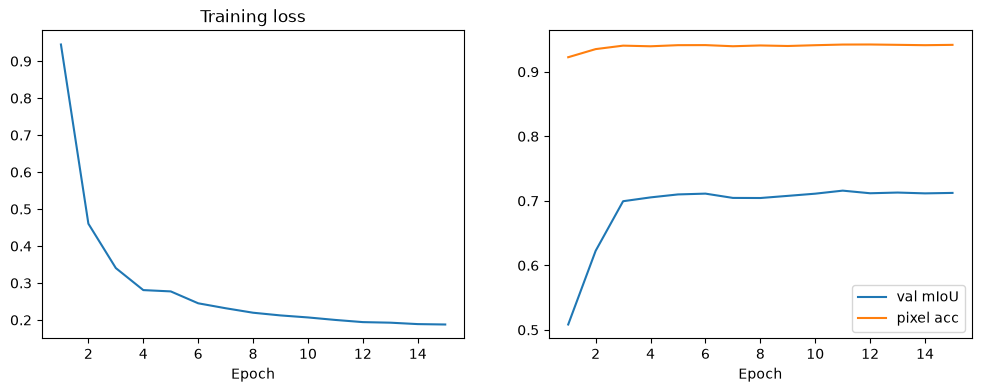

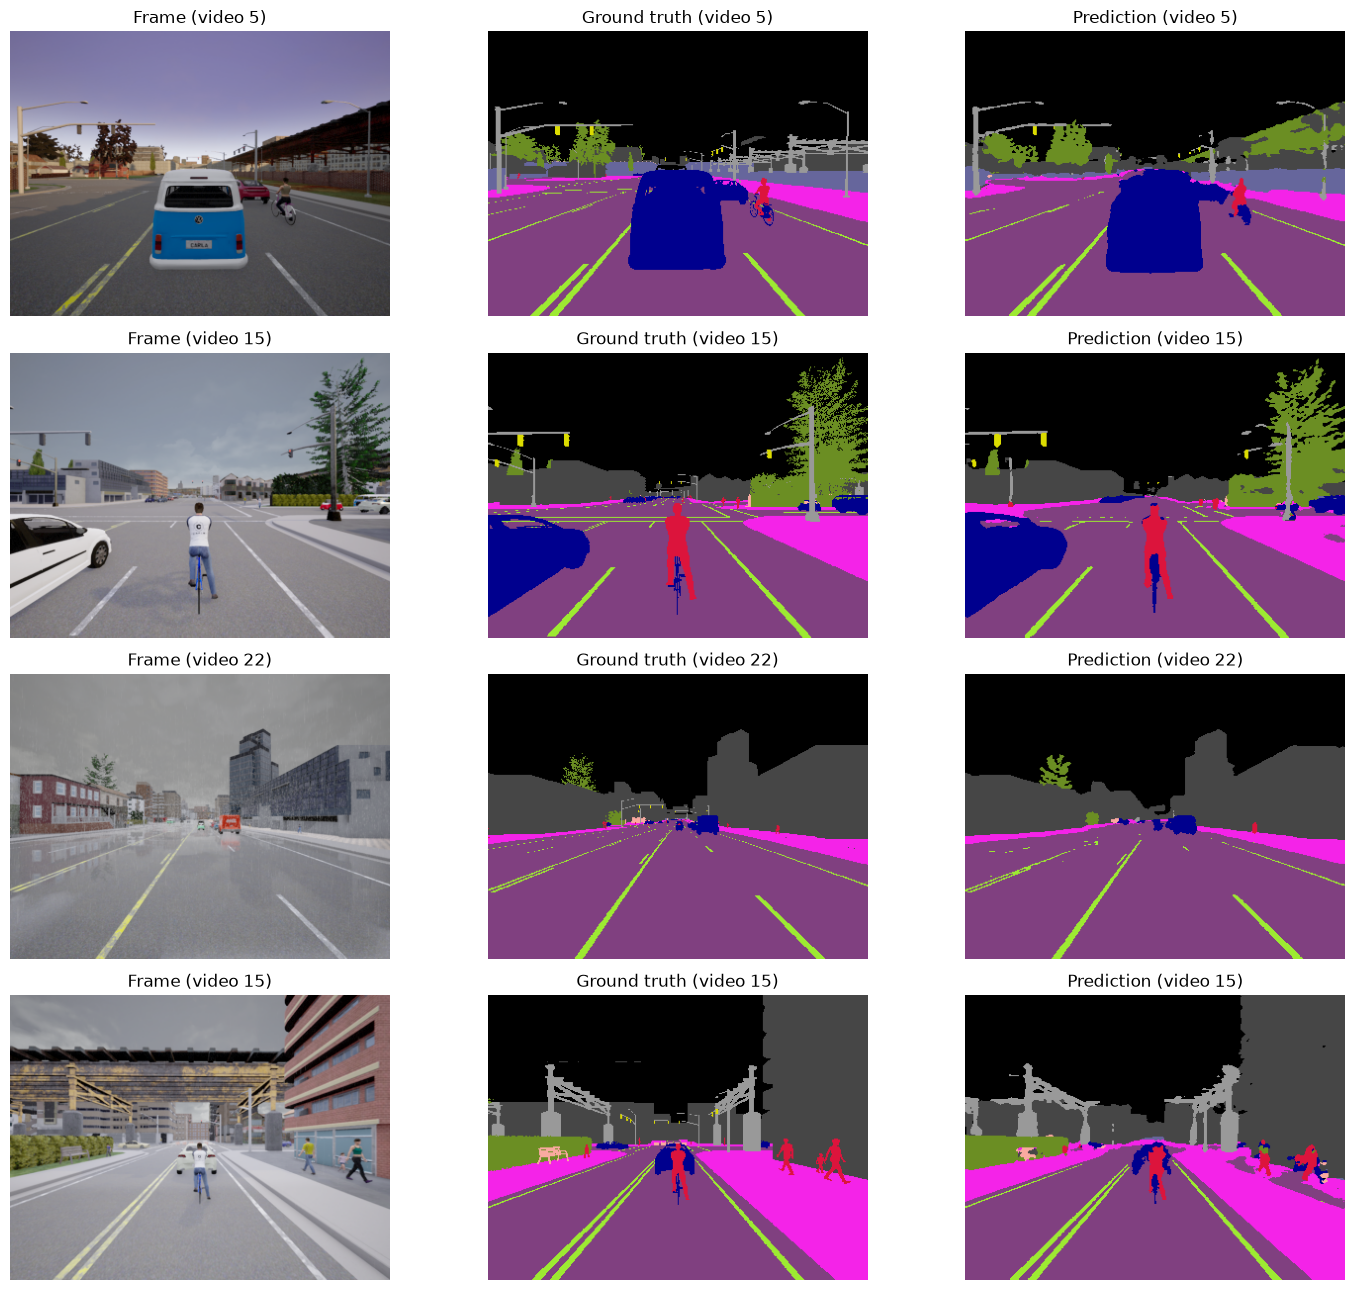

In [21]:
# Load the best model saved during training
model.load_state_dict(torch.load("unet_best.pth", map_location=device))
model.eval()
palette = np.array(class_rgb_values["rgb"].tolist(), dtype=np.uint8)

def predict(x_uint8):
    x = (x_uint8.astype(np.float32) / 255 - MEAN) / STD
    x = torch.from_numpy(x.transpose(0, 3, 1, 2)).to(device)
    with torch.no_grad():
        return model(x).argmax(1)

def cm_for(idx):
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    for s in range(0, len(idx), 8):
        b = idx[s:s + 8]
        cm += confusion(predict(X[b]), torch.from_numpy(Y[b]).long().to(device), NUM_CLASSES)
    return cm

def metrics(cm):
    tp = cm.diag().float()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).float()
    precision = tp / cm.sum(0).float()
    recall = tp / cm.sum(1).float()
    return iou.cpu().numpy(), precision.cpu().numpy(), recall.cpu().numpy(), (tp.sum() / cm.sum()).item()

# 1. Per-class results on all validation videos
val_idx = np.where(is_val)[0]
iou, prec, rec, acc = metrics(cm_for(val_idx))
results = pd.DataFrame({"class": class_names, "IoU": iou, "precision": prec, "recall": rec}).round(3)
display(results)
print(f"mIoU: {np.nanmean(iou):.3f} | pixel accuracy: {acc:.3f}")

# 2. Results per weather type
rows = []
for w in video_info["weather"].unique():
    vids = [v for v in val_videos if video_info.loc[video_info["Index"] == v, "weather"].item() == w]
    if not vids:
        continue
    i, _, _, a = metrics(cm_for(np.where(np.isin(V, vids))[0]))
    rows.append({"weather": w, "videos": vids, "mIoU": round(np.nanmean(i), 3), "pixel acc": round(a, 3)})
display(pd.DataFrame(rows))

# 3. Training curves
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(h) + 1), h[:, 0]); ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch")
ax[1].plot(range(1, len(h) + 1), h[:, 1], label="val mIoU")
ax[1].plot(range(1, len(h) + 1), h[:, 2], label="pixel acc"); ax[1].legend(); ax[1].set_xlabel("Epoch")
plt.show()

# 4. Example predictions: frame | ground truth | prediction
samples = np.random.default_rng(0).choice(val_idx, 4, replace=False)
preds = predict(X[samples]).cpu().numpy()
fig, ax = plt.subplots(4, 3, figsize=(15, 13))
for r, (i, p) in enumerate(zip(samples, preds)):
    gt = palette[np.where(Y[i] == 255, 0, Y[i])]
    for c, (img, title) in enumerate([(X[i], "Frame"), (gt, "Ground truth"), (palette[p], "Prediction")]):
        ax[r, c].imshow(img); ax[r, c].set_title(f"{title} (video {V[i]})"); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

Video: 1 | ['Sunny' 'Driving + Traffic am'] | 171 frames


action
BRAKE        82
CRUISE       43
FOLLOW       29
SLOW DOWN    17
Name: frames, dtype: int64

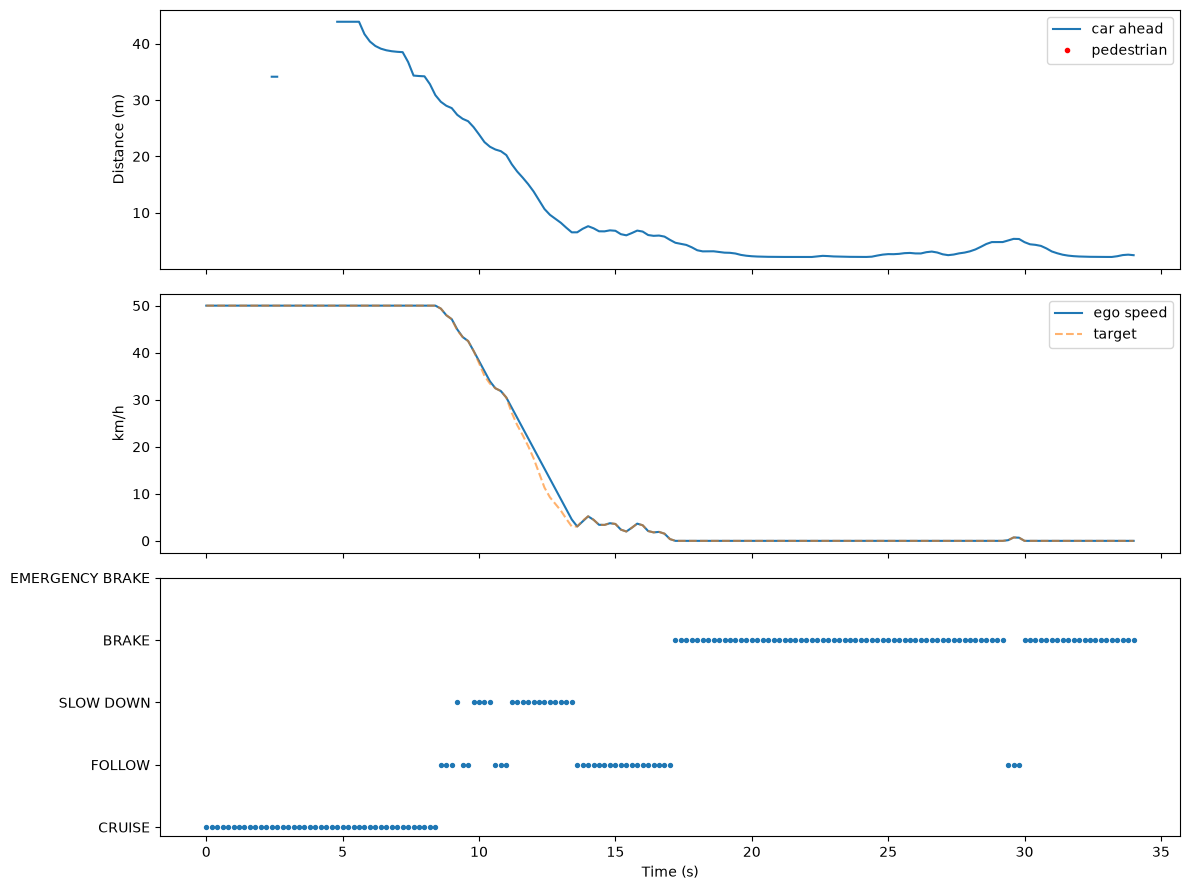

Saved demo video: acc_demo.mp4


In [22]:
# ===== Assumptions (state these in your report) =====
FOV_DEG    = 90                      # CARLA default camera field of view
CAM_HEIGHT = 1.6                     # metres above the road (assumed)
HORIZON_Y  = IMG_H // 2              # camera assumed to look straight ahead
FOCAL      = (IMG_W / 2) / np.tan(np.radians(FOV_DEG / 2))
DT         = FRAME_STEP / 10         # 10 Hz video, every 2nd frame -> 0.2 s

# ===== Cruise-control settings =====
SET_SPEED      = 50 / 3.6            # driver's chosen speed: 50 km/h in m/s
TIME_GAP       = 1.8                 # seconds of following distance
D_MIN          = 5.0                 # metres to keep when stopped
PED_STOP_DIST  = 15.0                # brake hard for a pedestrian closer than this
ACCEL, DECEL, EMERG_DECEL = 1.5, 3.0, 7.0   # m/s^2
MIN_PIXELS     = 30                  # ignore tiny detections (noise)

CAR, PED = class_names.index("Car"), class_names.index("Pedestrian")

# Ego-lane region: trapezoid in front of the car
roi = np.zeros((IMG_H, IMG_W), np.uint8)
roi_pts = np.array([[int(IMG_W*.25), IMG_H-1], [int(IMG_W*.75), IMG_H-1],
                    [int(IMG_W*.53), HORIZON_Y+5], [int(IMG_W*.47), HORIZON_Y+5]], np.int32)
cv2.fillPoly(roi, [roi_pts], 1)
roi = roi.astype(bool)

def nearest(mask, cls):
    """Distance (m) to the closest object of this class in our lane, plus its pixels."""
    m = (mask == cls) & roi
    if m.sum() < MIN_PIXELS:
        return None, None
    rows = np.where(m.sum(1) >= 3)[0]
    if len(rows) == 0 or rows.max() <= HORIZON_Y:
        return None, None
    return FOCAL * CAM_HEIGHT / (rows.max() - HORIZON_Y), m

# ===== Knowledge base: the rules =====
def decide(d_car, d_ped, v):
    if d_ped is not None and d_ped < PED_STOP_DIST:
        return "EMERGENCY BRAKE", 0.0, EMERG_DECEL      # R1: pedestrian close in our lane
    if d_car is None:
        return "CRUISE", SET_SPEED, DECEL                # R2: lane is free
    if d_car < D_MIN:
        return "BRAKE", 0.0, EMERG_DECEL                 # R3: car dangerously close
    v_safe = (d_car - D_MIN) / TIME_GAP                  # speed that keeps the time gap
    if v_safe < v - 0.5:
        return "SLOW DOWN", v_safe, DECEL                # R4: too fast for this gap
    if v_safe < SET_SPEED:
        return "FOLLOW", v_safe, DECEL                   # R5: follow the car ahead
    return "CRUISE", SET_SPEED, DECEL                    # R6: car ahead is far away

# ===== Pick a validation video with traffic =====
cand = video_info[video_info["Index"].isin(val_videos) &
                  video_info["driving_scenario"].str.contains("Traffic", case=False)]
VIDEO_ID = int(cand["Index"].iloc[0]) if len(cand) else val_videos[0]
idx = np.where(V == VIDEO_ID)[0]
print("Video:", VIDEO_ID, "|", video_info.loc[video_info["Index"] == VIDEO_ID,
      ["weather", "driving_scenario"]].values[0], "|", len(idx), "frames")

masks = np.concatenate([predict(X[idx[s:s+8]]).cpu().numpy() for s in range(0, len(idx), 8)])

# ===== Run the controller frame by frame =====
log, v, d_prev = [], SET_SPEED, None
writer = cv2.VideoWriter("acc_demo.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 1 / DT, (IMG_W * 2, IMG_H))
for t, (i, mask) in enumerate(zip(idx, masks)):
    d_car, car_px = nearest(mask, CAR)
    d_ped, _ = nearest(mask, PED)
    if d_car is not None and d_prev is not None:
        d_car = 0.6 * d_prev + 0.4 * d_car                # smooth noisy distance
    d_prev = d_car

    action, v_target, dec = decide(d_car, d_ped, v)
    v += np.clip(v_target - v, -dec * DT, ACCEL * DT)     # realistic speed change
    log.append({"time_s": t * DT, "action": action, "car_dist_m": d_car,
                "ped_dist_m": d_ped, "speed_kmh": v * 3.6, "target_kmh": v_target * 3.6})

    # Demo video frame: camera | segmentation, with lane area, detection and status
    left = X[i].copy(); right = palette[mask].copy()
    for img in (left, right):
        cv2.polylines(img, [roi_pts], True, (255, 255, 0), 1)
        if car_px is not None:
            ys, xs = np.where(car_px)
            cv2.rectangle(img, (xs.min(), ys.min()), (xs.max(), ys.max()), (255, 0, 0), 2)
    col = {"CRUISE": (0,200,0), "FOLLOW": (0,200,200), "SLOW DOWN": (255,165,0)}.get(action, (255,0,0))
    cv2.putText(left, action, (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
    cv2.putText(left, f"{v*3.6:4.1f} km/h", (8, 46), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,255,255), 1)
    if d_car is not None:
        cv2.putText(left, f"car {d_car:4.1f} m", (8, 68), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,255,255), 1)
    writer.write(cv2.cvtColor(np.hstack([left, right]), cv2.COLOR_RGB2BGR))
writer.release()

log = pd.DataFrame(log)
display(log["action"].value_counts().rename("frames"))

# ===== Charts =====
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(log["time_s"], log["car_dist_m"], label="car ahead")
ax[0].plot(log["time_s"], log["ped_dist_m"], "r.", label="pedestrian")
ax[0].set_ylabel("Distance (m)"); ax[0].legend()
ax[1].plot(log["time_s"], log["speed_kmh"], label="ego speed")
ax[1].plot(log["time_s"], log["target_kmh"], "--", alpha=.6, label="target")
ax[1].set_ylabel("km/h"); ax[1].legend()
acts = ["CRUISE", "FOLLOW", "SLOW DOWN", "BRAKE", "EMERGENCY BRAKE"]
ax[2].scatter(log["time_s"], log["action"].map(acts.index), s=8)
ax[2].set_yticks(range(len(acts))); ax[2].set_yticklabels(acts); ax[2].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()
print("Saved demo video: acc_demo.mp4")

In [23]:
import gc, time

RESULTS_CSV = "experiments.csv"

def build_data(w, h, step=2):
    path = rf"data\cache_{w}x{h}_step{step}.npz"
    if os.path.exists(path):
        d = np.load(path); return d["X"], d["Y"], d["V"]
    Xs, Ys, Vs = [], [], []
    for v in tqdm(range(len(video_info)), desc=f"Caching {w}x{h}"):
        files = sorted(glob.glob(os.path.join(images_dir, f"Video_{v:03d}", "*.png")))[::step]
        for f in files:
            lf = os.path.join(labels_dir, f"Video_{v:03d}", os.path.basename(f))
            img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
            lab = cv2.cvtColor(cv2.imread(lf), cv2.COLOR_BGR2RGB)
            Xs.append(cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA))
            Ys.append(cv2.resize(to_mask(lab), (w, h), interpolation=cv2.INTER_NEAREST))
            Vs.append(v)
    Xs, Ys, Vs = np.stack(Xs), np.stack(Ys), np.array(Vs)
    np.savez(path, X=Xs, Y=Ys, V=Vs)
    return Xs, Ys, Vs

class AugDataset(Dataset):
    def __init__(self, X, Y, idx, aug="flip"):
        self.X, self.Y, self.idx, self.aug = X, Y, idx, aug
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        x, y = self.X[i], self.Y[i]
        if self.aug in ("flip", "strong") and np.random.rand() < 0.5:
            x, y = x[:, ::-1], y[:, ::-1]
        x = np.ascontiguousarray(x).astype(np.float32)
        if self.aug == "strong":
            x = x * np.random.uniform(0.7, 1.3) + np.random.uniform(-25, 25)   # contrast / brightness
            if np.random.rand() < 0.3: x = cv2.GaussianBlur(x, (5, 5), 0)      # blur (rain on lens)
            if np.random.rand() < 0.3: x = x + np.random.normal(0, 8, x.shape) # sensor noise
            if np.random.rand() < 0.2: x = x * 0.7 + 160 * 0.3                  # haze / fog
            x = np.clip(x, 0, 255)
        x = (x / 255 - MEAN) / STD
        return (torch.from_numpy(x.transpose(2, 0, 1).astype(np.float32)),
                torch.from_numpy(np.ascontiguousarray(y)).long())

def evaluate(model, X, Y, idx, n):
    model.eval()
    cm = torch.zeros(n, n, dtype=torch.long, device=device)
    with torch.no_grad():
        for s in range(0, len(idx), 8):
            b = idx[s:s + 8]
            x = (X[b].astype(np.float32) / 255 - MEAN) / STD
            x = torch.from_numpy(x.transpose(0, 3, 1, 2)).to(device)
            cm += confusion(model(x).argmax(1), torch.from_numpy(Y[b]).long().to(device), n)
    tp = cm.diag().float()
    iou = (tp / (cm.sum(0) + cm.sum(1) - tp).float()).cpu().numpy()
    return iou, (tp.sum() / cm.sum()).item()

def run_experiment(cfg, epochs):
    name, N = cfg["name"], NUM_CLASSES
    print(f"\n===== {name} =====")
    t0 = time.time()
    Xe, Ye, Ve = build_data(cfg["w"], cfg["h"])
    val = np.isin(Ve, val_videos)
    tr_idx, va_idx = np.where(~val)[0], np.where(val)[0]
    loader = DataLoader(AugDataset(Xe, Ye, tr_idx, cfg["aug"]),
                        batch_size=cfg["batch"], shuffle=True, num_workers=0)

    weight = None
    if cfg["class_weights"]:
        counts = np.bincount(Ye[tr_idx].ravel(), minlength=256)[:N].astype(np.float64)
        w = 1 / np.sqrt(counts / counts.sum() + 1e-6)
        weight = torch.tensor(np.clip(w / w.mean(), 0.2, 10), dtype=torch.float32, device=device)

    model = getattr(smp, cfg["arch"])(cfg["encoder"], encoder_weights="imagenet", classes=N).to(device)
    ce = torch.nn.CrossEntropyLoss(weight=weight, ignore_index=255)
    dice = smp.losses.DiceLoss(mode="multiclass", ignore_index=255)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best, ckpt = -1, f"model_{name}.pth"
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in tqdm(loader, desc=f"{name} {ep}/{epochs}", leave=False):
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = ce(out, yb) + dice(out, yb)
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        iou, acc = evaluate(model, Xe, Ye, va_idx, N)
        miou = np.nanmean(iou)
        print(f"  epoch {ep:2d} | val mIoU {miou:.3f} | pixel acc {acc:.3f}")
        if miou > best:
            best = miou; torch.save(model.state_dict(), ckpt)

    model.load_state_dict(torch.load(ckpt, map_location=device))
    iou, acc = evaluate(model, Xe, Ye, va_idx, N)
    row = {"name": name, "arch": cfg["arch"], "encoder": cfg["encoder"],
           "resolution": f'{cfg["w"]}x{cfg["h"]}', "aug": cfg["aug"],
           "class_weights": cfg["class_weights"], "epochs": epochs,
           "mIoU": round(float(np.nanmean(iou)), 4), "pixel_acc": round(acc, 4)}
    for c in ["Car", "Pedestrian", "Pole", "Traffic Sign"]:
        row[f"IoU_{c}"] = round(float(iou[class_names.index(c)]), 4)
    for w_ in video_info["weather"].unique():
        vids = [v for v in val_videos if video_info.loc[video_info["Index"] == v, "weather"].item() == w_]
        if vids:
            wi, _ = evaluate(model, Xe, Ye, np.where(np.isin(Ve, vids))[0], N)
            row[f"mIoU_{w_}"] = round(float(np.nanmean(wi)), 4)
    row["minutes"] = round((time.time() - t0) / 60, 1)

    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", index=False,
                               header=not os.path.exists(RESULTS_CSV))
    print(row)
    del model, opt, loader; gc.collect(); torch.cuda.empty_cache()

In [24]:
EPOCHS_EXP = 10
base = dict(arch="Unet", encoder="resnet34", w=384, h=288, batch=8, aug="flip", class_weights=False)
experiments = [
    {**base, "name": "baseline"},
    {**base, "name": "strong_aug",    "aug": "strong"},
    {**base, "name": "class_weights", "class_weights": True},
    {**base, "name": "deeplabv3plus", "arch": "DeepLabV3Plus"},
    {**base, "name": "resnet50",      "encoder": "resnet50", "batch": 6},
    {**base, "name": "hires_512",     "w": 512, "h": 384, "batch": 4},
]

done = set(pd.read_csv(RESULTS_CSV)["name"]) if os.path.exists(RESULTS_CSV) else set()
for cfg in experiments:
    if cfg["name"] in done:
        print("Already done, skipping:", cfg["name"]); continue
    try:
        run_experiment(cfg, EPOCHS_EXP)
    except torch.cuda.OutOfMemoryError:
        print(f"!! {cfg['name']} ran out of GPU memory - try a smaller 'batch' for it")
        gc.collect(); torch.cuda.empty_cache()


===== baseline =====


baseline 1/10:   0%|          | 0/533 [00:00<?, ?it/s]

  epoch  1 | val mIoU 0.569 | pixel acc 0.929


baseline 2/10:   0%|          | 0/533 [00:00<?, ?it/s]

  epoch  2 | val mIoU 0.626 | pixel acc 0.930


baseline 3/10:   0%|          | 0/533 [00:00<?, ?it/s]

... (116 outputs left out)

hires_512 9/10:   0%|          | 0/1065 [00:00<?, ?it/s]

  epoch  9 | val mIoU 0.743 | pixel acc 0.952


hires_512 10/10:   0%|          | 0/1065 [00:00<?, ?it/s]

  epoch 10 | val mIoU 0.745 | pixel acc 0.952
{'name': 'hires_512', 'arch': 'Unet', 'encoder': 'resnet34', 'resolution': '512x384', 'aug': 'flip', 'class_weights': False, 'epochs': 10, 'mIoU': 0.7456, 'pixel_acc': 0.9506, 'IoU_Car': 0.9041, 'IoU_Pedestrian': 0.6248, 'IoU_Pole': 0.464, 'IoU_Traffic Sign': 0.5846, 'mIoU_Sunny': 0.7272, 'mIoU_Rainy': 0.6011, 'mIoU_Cloudy': 0.6882, 'minutes': 44.6}
